## HW2



## Katya Sumwalt

In [1]:
import xarray as xr 
import matplotlib.pyplot as plt 
import numpy as np 
import scipy.stats as st
import statistics
from scipy.stats import norm
from scipy.stats import uniform
from HW2_load_data_push_to_git_KSUMWALT import load_in_pier_data as lp

got pier data for 2015: data, time array


## Problem 1. Plot records of temperature and pressure from 2 years. Are there obvious discrepancies between the two years? What years are covered? Any other observations?

Summary of responses: There were no obvious discrepancies between the two other than the peak in temperature for 2015 being in septemeber, while in 2016 the peak temperature was in august. The years that are covered are 2016 and 2015. Some observation described below include the observation of a daily and seasonal cycle, minimums in temeprature in june, bigger swings in temperature in summer due to a more stratified (warmer surface) ocean and mixing by tides. 

In [2]:
# path_to_data = '/Users/kat/Desktop/GradSchool/SIOC221/HW/HW1/HW1_data/'
# data_year_2015 = xr.open_dataset(f'{path_to_data}scripps_pier-2015.nc')#data is samples every 6 minutes, but unevenly
# data_year_2016 = xr.open_dataset(f'{path_to_data}scripps_pier-2016.nc') #data is sampled every 5 minutes, 34 seconds, but not evenly spaced like the above data
# time_array_2015 = np.sort(np.asarray(data_year_2015.time).astype('datetime64[s]'))
# time_array_2016 =np.sort(np.asarray(data_year_2016.time).astype('datetime64[s]'))

In [3]:
data_year_2015,time_array_2015 = lp(2015)
data_year_2016,time_array_2016 = lp(2016)

got pier data for 2015: data, time array
got pier data for 2016: data, time array


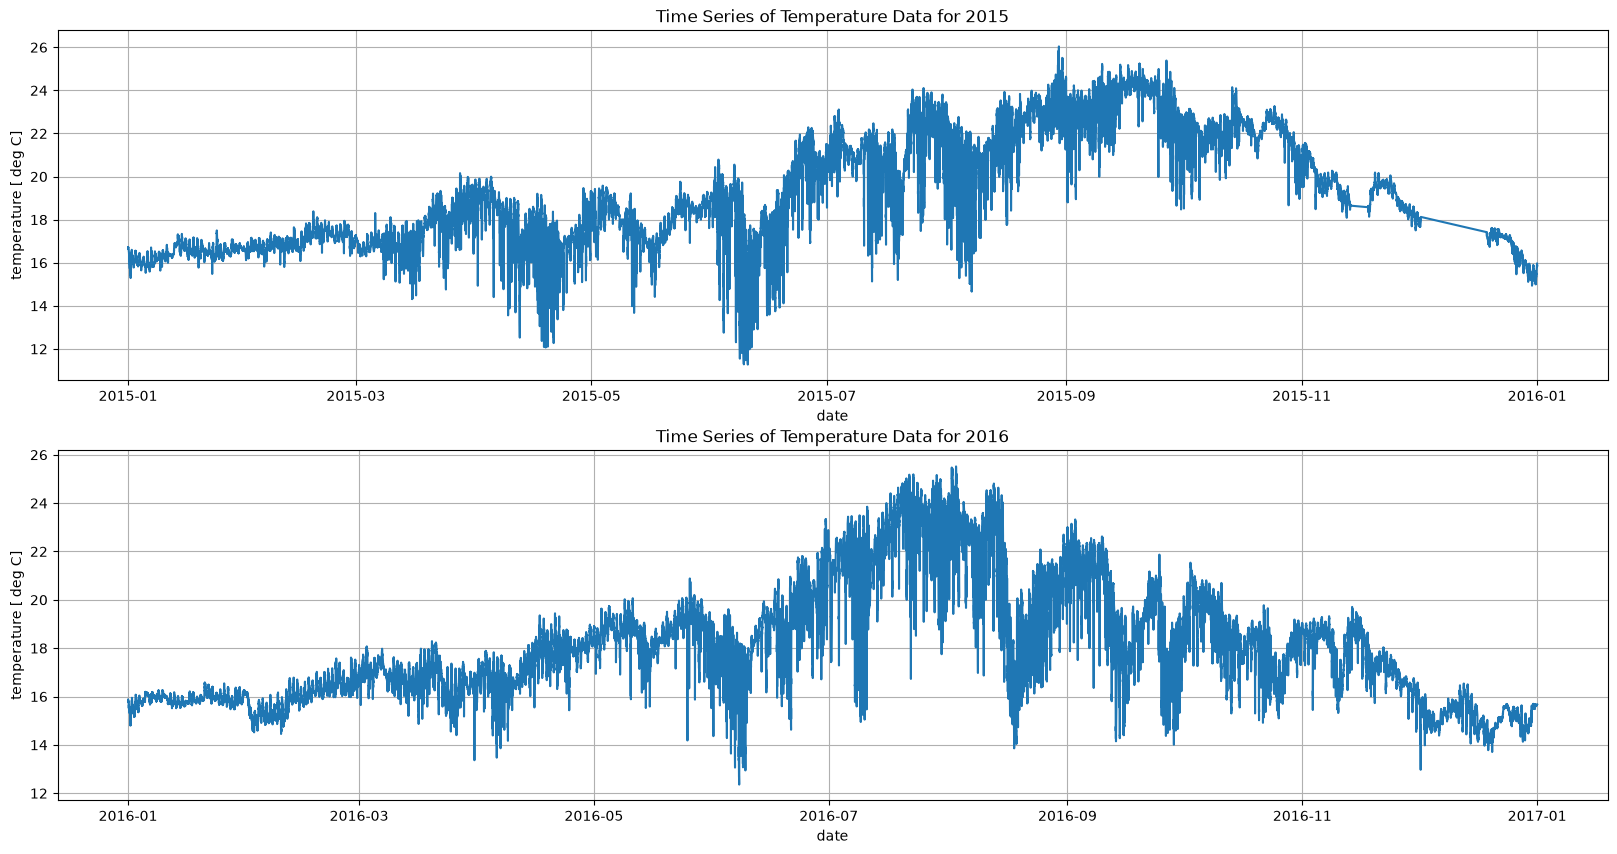

In [4]:
plt.figure(figsize = (20,10))
plt.subplot(211) 
plt.title('Time Series of Temperature Data for 2015')
plt.plot(time_array_2015,data_year_2015.temperature)
plt.xlabel('date')
plt.ylabel('temperature [ deg C]')
plt.grid()
plt.subplot(212) 
plt.title('Time Series of Temperature Data for 2016')
plt.plot(time_array_2016,data_year_2016.temperature)
plt.xlabel('date')
plt.ylabel('temperature [ deg C]')
plt.grid()


There do not appear to be any obvious discrepancies in temperature between the two years. It does appear that around august for 2016 there is a low in temperature that does not occur as intensely in 2015. The years that are covered are 2016 and 2017. Some other observations include that there is a minimum in temperature in spring and a maximum during august. It does appear that the maximum temperature for 2015 was later in the year than for 2016. The maximum for 2016 also appears to be slightly lower. Another feature I found interesting was that in june there is a minimum in temperature in both of these years. 

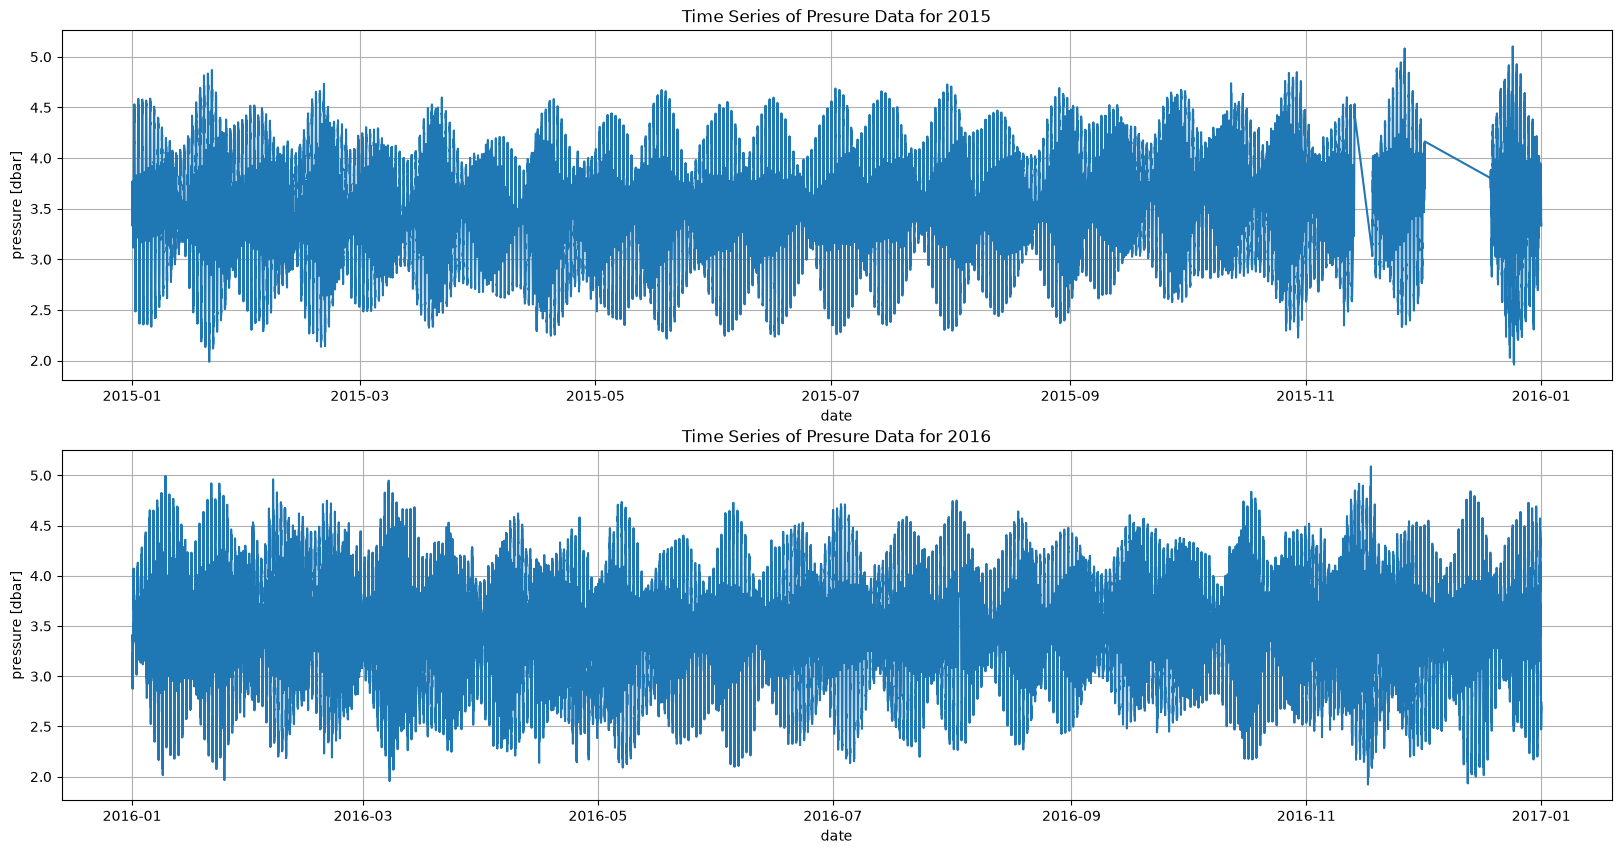

In [5]:
plt.figure(figsize = (20,10))
plt.subplot(211) 
plt.title('Time Series of Presure Data for 2015')
plt.plot(time_array_2015,data_year_2015.pressure)
plt.xlabel('date')
plt.ylabel('pressure [dbar]')
plt.grid()
plt.subplot(212) 
plt.title('Time Series of Presure Data for 2016')
plt.plot(time_array_2016,data_year_2016.pressure)
plt.xlabel('date')
plt.ylabel('pressure [dbar]')
plt.grid()

The years that are covered for the pressure include 2015 and 2016. There are not imediately any obvious discrepancies between the two years. Some observations include that there appears to bea a seasonal cycle in the pressure, where during the summer months ot between may and september the amplitude of the lower frequency pressure fluctuations appears to dominate the signal while closer to winter the higher frequency waves tends to dominate. The higher frequency signal is tied to the semi-diurnal tide and the lower frequency is dominated by the diurnal tide. One observation that is hard to parse visually is that at the beginning of 2016 it looks like thier fluctuations in pressure are greater than during 2015, maybe that could be understood with further analysis

## Problem 2: For each quantity, evaluate whether the sample mean between the two years is consistent within error bars. Do you obtain different results if you subsample the data at (say) once per day?

Summary of responses: The sample mean for both quantities between the two years is not consistent within error bars. I obtain different values for the SEM and the temperatre mean if I subsample the data, but the inconsistency remains.

In [6]:
combined_2015_2016_temperature  = xr.concat([data_year_2015.temperature,data_year_2016.temperature], dim = 'time')
combined_2015_2016_pressure  = xr.concat([data_year_2015.pressure,data_year_2016.pressure], dim = 'time')

In [7]:
n_2015 = len(data_year_2015.temperature)
n_2016 = len(data_year_2016.temperature)
total_n = n_2015 + n_2016
temperature_2015_sample_mean = (n_2015 / total_n) * data_year_2015.temperature.mean()
temperature_2016_sample_mean = (n_2016 / total_n) * data_year_2016.temperature.mean()
temp_mean_combined = temperature_2015_sample_mean + temperature_2016_sample_mean #18.7147

pressure_2015_sample_mean = (n_2015 / total_n) * data_year_2015.pressure.mean()
pressure_2016_sample_mean = (n_2016 / total_n) * data_year_2016.pressure.mean()
pressure_mean_combined =pressure_2015_sample_mean + pressure_2016_sample_mean

sem_temp = st.sem(combined_2015_2016_temperature)
sem_pressure = st.sem(combined_2015_2016_pressure)

print(f' combined temperature mean: {temp_mean_combined.values:.3f}+/- sem:{sem_temp:.3f}')
print(f' combined pressure mean: {pressure_mean_combined.values:.3f}+/- sem: {sem_pressure:.3f}')
print(f' 2015 mean temp: {data_year_2015.temperature.mean().values:.3f} +/- {st.sem(data_year_2015.temperature):.3f}, pressure: {data_year_2015.pressure.mean().values:.3f} +/- {st.sem(data_year_2015.pressure):.3f}')
print(f' 2016 mean temp: {data_year_2016.temperature.mean().values:.3f} +/- {st.sem(data_year_2016.temperature):.3f}, pressure: {data_year_2016.pressure.mean().values:.3f} +/- {st.sem(data_year_2016.pressure):.3f}')


 combined temperature mean: 18.717+/- sem:0.006
 combined pressure mean: 3.478+/- sem: 0.001
 2015 mean temp: 19.254 +/- 0.009, pressure: 3.501 +/- 0.002
 2016 mean temp: 18.250 +/- 0.008, pressure: 3.459 +/- 0.002


For 2015 the mean temperature with its error does not fall within the combined temperature mean and SEM values indicating that the sample mean is not consistent between the two years. The 2016 mean temperature similarly does not fall within the combined mean and SEM values indicating that the sample mean is not consistent between the two years. 2016 was an el nino year so that maybe could be why they are not consistent. For the pressure there is in 2015 pressure values that do not overlap with the combined pressure value mean, it is the same fot 2016. 

Subsampling the Data and Running the Check Again

In [8]:
##length between eeach sample
temp_2015_time_sampling_mean = (np.mean(np.diff(time_array_2015))) / np.timedelta64(1, 's') #383 seconds, #division by np.timedelta was a correction from clauds
temp_2016_time_sampling_mean = np.mean(np.diff(time_array_2016))/ np.timedelta64(1, 's') #334
subsample_at_freq_2015 = int((24 * 60 *60)/temp_2015_time_sampling_mean)
subsample_at_freq_2016 = int((24 * 60 *60)/temp_2016_time_sampling_mean)
subsampled_data_15_t,subsampled_data_15_p  = data_year_2015.temperature[::subsample_at_freq_2015],data_year_2015.pressure[::subsample_at_freq_2015]
subsampled_data_16_t,subsampled_data_16_p  = data_year_2016.temperature[::subsample_at_freq_2016],data_year_2016.pressure[::subsample_at_freq_2016]


In [9]:
combined_subsampled_temp = xr.concat([subsampled_data_15_t,subsampled_data_16_t], dim = 'time')
combined_subsampled_pressure = xr.concat([subsampled_data_15_p,subsampled_data_16_p],dim = 'time')
n_2015 = len(subsampled_data_15_t)
n_2016 = len(subsampled_data_16_t)
total_n = n_2015 + n_2016
temperature_2015_sample_mean = (n_2015 / total_n) * subsampled_data_15_t.mean()
temperature_2016_sample_mean = (n_2016 / total_n) * subsampled_data_16_t.mean()
temp_mean_combined = temperature_2015_sample_mean + temperature_2016_sample_mean #18.7147

pressure_2015_sample_mean = (n_2015 / total_n) * subsampled_data_15_p.mean()
pressure_2016_sample_mean = (n_2016 / total_n) * subsampled_data_16_p.mean()
pressure_mean_combined =pressure_2015_sample_mean + pressure_2016_sample_mean

sem_temp = st.sem(combined_subsampled_temp)
sem_pressure = st.sem(combined_subsampled_pressure)

print(f' combined temperature mean: {temp_mean_combined.values:.2f}+/- sem:{sem_temp:.2f}')
print(f' combined pressure mean: {pressure_mean_combined.values:.2f}+/- sem: {sem_pressure:.2f}')
print(f' 2015 mean temp: {subsampled_data_15_t.mean().values:.1f} +/- {st.sem(subsampled_data_15_t):.1f}, pressure: {subsampled_data_15_p.mean().values:.2f} +/- {st.sem(subsampled_data_15_p):.2f}')
print(f' 2016 mean temp: {subsampled_data_16_t.mean().values:.1f} +/- {st.sem(subsampled_data_16_t):.1f}, pressure: {subsampled_data_16_p.mean().values:.2f} +/- {st.sem(subsampled_data_16_p):.2f}')


 combined temperature mean: 18.72+/- sem:0.10
 combined pressure mean: 3.49+/- sem: 0.02
 2015 mean temp: 19.2 +/- 0.1, pressure: 3.50 +/- 0.03
 2016 mean temp: 18.2 +/- 0.1, pressure: 3.48 +/- 0.03


We can see that there was a change in the mean temperature and the error bar for the combined subsampled data. However the 2015 mean temperature still does not fall within the combined tempreature mean and the 2016 mean similarly does not fall within the error bar range for the combined temperature. We can see however that the error bars for both are bigger. For the pressure, we can see that the 2015 pressure fall within the combined pressure mean now, same witthe the 2016 mean pressure. This may be attributed to the fact that the erro bar for the combined value is just larger now. 

## Problem 3:  Variance. For each quantity, evaluate whether the variance from the two years are consistent. Do you obtain different results if you subsample the data at (say)once per day?

Summary of responses: The variance 2015 for temperature is consistent with the grouped together mean and error bars, but not the 2016 variance. The 2015 and 2016 variance are not consistent with each other. The variance pressure is consistent between the two years and the combined. The overall result for subsampling the data remains the same, however some of the numbers are different, i.e. subsampling the data results in the variance for the pressure to get closer or more consistent.

In [10]:
def calculate_standard_error_of_the_variance(arr): 
    N = len(arr)
    ''' calculates the standard error of the varianc of an array'''
    ## standard error of the variance gives std. /sqrt(2/N-1)
    sd = np.std(arr, ddof=1)
    sev = sd**2*np.sqrt(2/(N-1)) 
    return sev

In [11]:
variance_of_2015_temp = statistics.variance(data_year_2015.temperature.values)
variance_of_2015_pressure = statistics.variance(data_year_2015.pressure.values)
variance_of_2016_temp = statistics.variance(data_year_2016.temperature.values)
variance_of_2016_pressure = statistics.variance(data_year_2016.pressure.values)
variance_of_combined_temperature = statistics.variance(combined_2015_2016_temperature.values)
variance_of_combined_pressure = statistics.variance(combined_2015_2016_pressure.values)

sev_2015_temp = calculate_standard_error_of_the_variance(data_year_2015.temperature.values)
sev_2016_temp = calculate_standard_error_of_the_variance(data_year_2016.temperature.values)
sev_2015_pressure = calculate_standard_error_of_the_variance(data_year_2015.pressure.values)
sev_2016_pressure = calculate_standard_error_of_the_variance(data_year_2016.pressure.values)
sev_of_combined_temp = calculate_standard_error_of_the_variance(combined_2015_2016_temperature.values)
sev_of_combined_pressure =  calculate_standard_error_of_the_variance(combined_2015_2016_pressure.values)


print(f'variance of 2015 temp {variance_of_2015_temp:.2f} +\- {sev_2015_temp:.2f} ')
print(f'variance of 2016 temp {variance_of_2016_temp:.2f} +\- {sev_2016_temp:.2f}')
print(f'variance of 2015 pressure {variance_of_2015_pressure:.3f} +\- {sev_2015_pressure:.3f}')
print(f'variance of 2016 pressure {variance_of_2016_pressure:.3f} +\- {sev_2016_pressure:.3f}')
print(f'variance of combined temp {variance_of_combined_temperature:.2f} +\- {sev_of_combined_temp:.2f}')
print(f'variance of combined pressure {variance_of_combined_pressure:3f} +\- {sev_of_combined_pressure:.3f}')


variance of 2015 temp 6.81 +\- 0.03 
variance of 2016 temp 6.30 +\- 0.03
variance of 2015 pressure 0.243 +\- 0.001
variance of 2016 pressure 0.244 +\- 0.001
variance of combined temp 6.79 +\- 0.02
variance of combined pressure 0.243749 +\- 0.001


In [12]:
#### SUBSAMPLED AT SAME FREQ AS BEFORE
subsampled_data_15_t,subsampled_data_15_p  = data_year_2015.temperature[::subsample_at_freq_2015],data_year_2015.pressure[::subsample_at_freq_2015]
subsampled_data_16_t,subsampled_data_16_p  = data_year_2016.temperature[::subsample_at_freq_2016],data_year_2016.pressure[::subsample_at_freq_2016]



variance_of_2015_temp = statistics.variance(subsampled_data_15_t.values)
variance_of_2015_pressure = statistics.variance(subsampled_data_15_p.values)
variance_of_2016_temp = statistics.variance(subsampled_data_16_t.values)
variance_of_2016_pressure = statistics.variance(subsampled_data_16_p.values)
variance_of_combined_temperature = statistics.variance(combined_subsampled_temp.values)
variance_of_combined_pressure = statistics.variance(combined_subsampled_pressure.values)

sev_2015_temp = calculate_standard_error_of_the_variance(subsampled_data_15_t.values)
sev_2016_temp = calculate_standard_error_of_the_variance(subsampled_data_16_t.values)
sev_2015_pressure = calculate_standard_error_of_the_variance(subsampled_data_15_p.values)
sev_2016_pressure = calculate_standard_error_of_the_variance(subsampled_data_16_p.values)
sev_of_combined_temp = calculate_standard_error_of_the_variance(combined_subsampled_temp.values)
sev_of_combined_pressure =  calculate_standard_error_of_the_variance(combined_subsampled_pressure.values)


print(f'variance of 2015 temp {variance_of_2015_temp:.2f} +\- {sev_2015_temp:.2f} ')
print(f'variance of 2016 temp {variance_of_2016_temp:.2f} +\- {sev_2016_temp:.2f}')
print(f'variance of 2015 pressure {variance_of_2015_pressure:.3f} +\- {sev_2015_pressure:.3f}')
print(f'variance of 2016 pressure {variance_of_2016_pressure:.3f} +\- {sev_2016_pressure:.3f}')
print(f'variance of combined temp {variance_of_combined_temperature:.2f} +\- {sev_of_combined_temp:.2f}')
print(f'variance of combined pressure {variance_of_combined_pressure:3f} +\- {sev_of_combined_pressure:.3f}')

variance of 2015 temp 6.90 +\- 0.51 
variance of 2016 temp 6.43 +\- 0.48
variance of 2015 pressure 0.249 +\- 0.018
variance of 2016 pressure 0.249 +\- 0.018
variance of combined temp 6.90 +\- 0.36
variance of combined pressure 0.248971 +\- 0.013


Yes, I obtain different results if I subsample the data.

## Problem 4: Probability density functions. For both pressure and temperature, plot the pdfs for the two years on the same axes. Overplot the Gaussian and uniform distributions that have the observed mean and variance.

Text(0, 0.5, 'probability density')

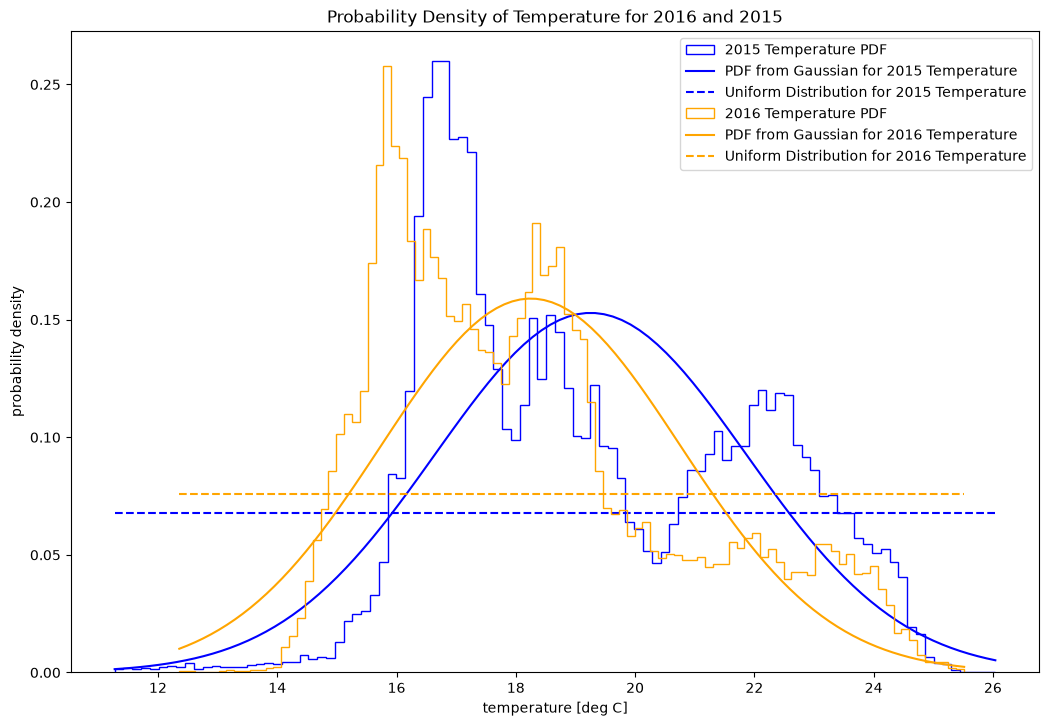

In [13]:
plt.figure(figsize = (15/1.2,10/1.2))
mean_2015_temp = float(data_year_2015.temperature.mean().values)
mean_2016_temp = float(data_year_2016.temperature.mean().values)

sigma_temp_2015 = np.sqrt(statistics.variance(data_year_2015.temperature.values))
sigma_temp_2016 = np.sqrt(statistics.variance(data_year_2016.temperature.values))

### PLOTTING OF NORMAL DIST BY https://stackoverflow.com/questions/10138085/how-to-plot-normal-distribution
x15 = np.linspace(float(data_year_2015.temperature.min().values), float(data_year_2015.temperature.max().values), 100)
xu15 = np.linspace(data_year_2015.pressure.values.min(), data_year_2015.pressure.values.max(), 1000)
x16 = np.linspace(float(data_year_2016.temperature.min().values), float(data_year_2016.temperature.max().values), 100)
xu16 = np.linspace(data_year_2016.pressure.values.min(), data_year_2016.pressure.values.max(), 1000)


plt.subplot()
plt.hist(data_year_2015.temperature,bins = 100, density = True, histtype='step', label = '2015 Temperature PDF', color = 'blue')
plt.plot(x15, st.norm.pdf(x15, mean_2015_temp, sigma_temp_2015), label = 'PDF from Gaussian for 2015 Temperature', color = 'blue')
plt.plot(x15, st.uniform.pdf(x15, loc=x15.min(), scale=x15.max()-x15.min()),color='blue', linestyle='--', label='Uniform Distribution for 2015 Temperature')


plt.hist(data_year_2016.temperature,bins = 100, density = True, histtype='step',label = '2016 Temperature PDF', color = 'orange') 
plt.plot(x16, st.norm.pdf(x16, mean_2016_temp, sigma_temp_2016), label = 'PDF from Gaussian for 2016 Temperature', color = 'orange')
plt.plot(x16, st.uniform.pdf(x16, loc=x16.min(), scale=x16.max()-x16.min()),color='orange', linestyle='--', label='Uniform Distribution for 2016 Temperature')
plt.legend(loc = 'upper right')
plt.title('Probability Density of Temperature for 2016 and 2015')
plt.xlabel('temperature [deg C]')
plt.ylabel('probability density')

Text(0, 0.5, 'probability density')

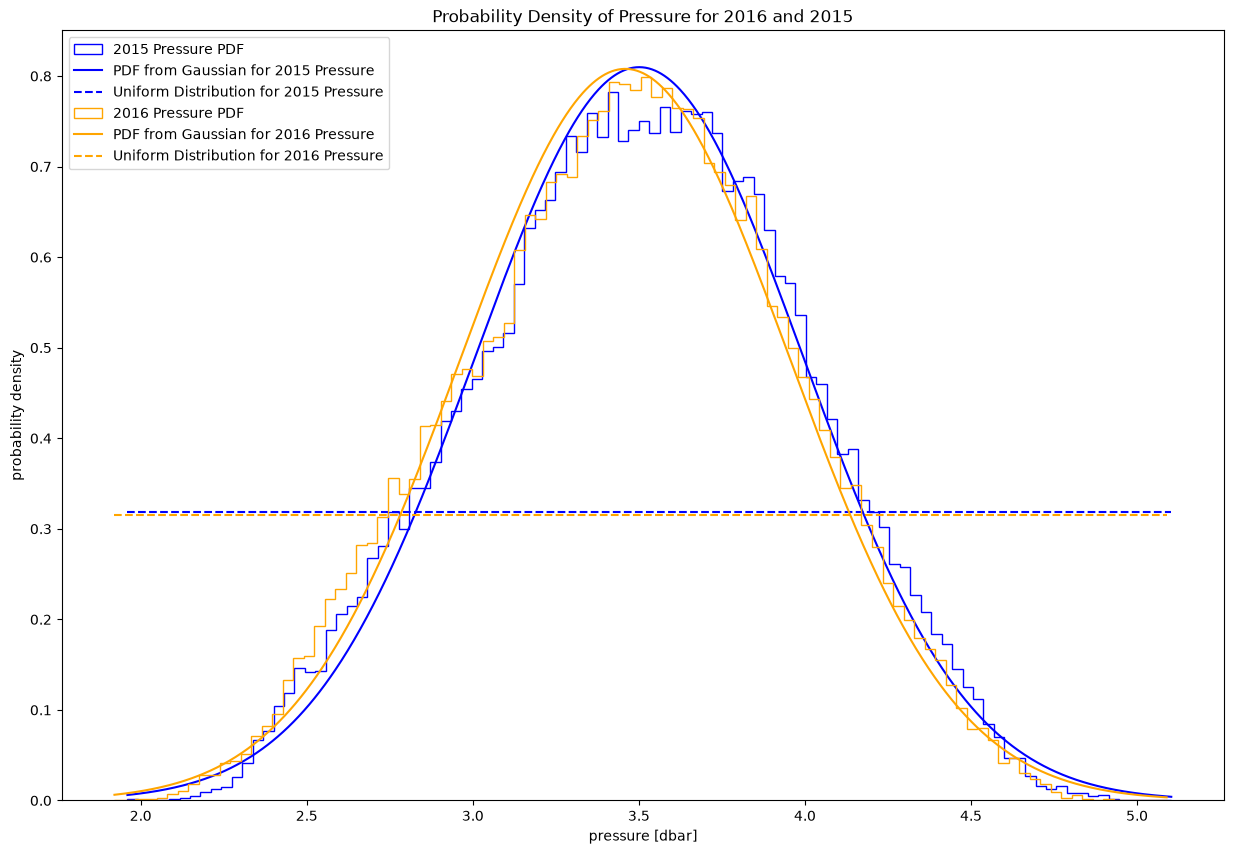

In [14]:
plt.figure(figsize = (15,10))
mean_2015_temp = float(data_year_2015.pressure.mean().values)
mean_2016_temp = float(data_year_2016.pressure.mean().values)

sigma_temp_2015 = np.sqrt(statistics.variance(data_year_2015.pressure.values))
sigma_temp_2016 = np.sqrt(statistics.variance(data_year_2016.pressure.values))

### PLOTTING OF NORMAL DIST BY https://stackoverflow.com/questions/10138085/how-to-plot-normal-distribution
xu15 = np.linspace(data_year_2015.pressure.values.min(), data_year_2015.pressure.values.max(), 1000)
xu16 = np.linspace(data_year_2016.pressure.values.min(), data_year_2016.pressure.values.max(), 1000)

plt.subplot()
plt.hist(data_year_2015.pressure,bins = 100, density = True, histtype='step', label = '2015 Pressure PDF', color = 'blue')
plt.plot(xu15, st.norm.pdf(xu15, mean_2015_temp, sigma_temp_2015), label = 'PDF from Gaussian for 2015 Pressure', color = 'blue')
plt.plot(xu15, st.uniform.pdf(xu15, loc=xu15.min(), scale=xu15.max()-xu15.min()),color='blue', linestyle='--', label='Uniform Distribution for 2015 Pressure')


plt.hist(data_year_2016.pressure,bins = 100, density = True, histtype='step',label = '2016 Pressure PDF', color = 'orange') 
plt.plot(xu16, st.norm.pdf(xu16, mean_2016_temp, sigma_temp_2016), label = 'PDF from Gaussian for 2016 Pressure', color = 'orange')
plt.plot(xu16, st.uniform.pdf(xu16, loc=xu16.min(), scale=xu16.max()-xu16.min()),color='orange', linestyle='--', label='Uniform Distribution for 2016 Pressure')
plt.legend(loc = 'upper left')
plt.title('Probability Density of Pressure for 2016 and 2015')
plt.xlabel('pressure [dbar]')
plt.ylabel('probability density')

## Problem 5: Extreme values. For each of the two years, compute the likelihood given the observed PDF, and a Gaussian PDF with the observed variance, of a temperature extreme value 3σ greater than the mean. Plot the CDF.

In [15]:
#find the likelihood of a temperature extreme value 3 sigma greater than the mean for observed PDF 
mean_2015_temp = float(data_year_2015.temperature.mean().values)
mean_2016_temp = float(data_year_2016.temperature.mean().values)
sigma_temp_2015 = np.sqrt(statistics.variance(data_year_2015.temperature.values))
sigma_temp_2016 = np.sqrt(statistics.variance(data_year_2016.temperature.values))

x15 = np.linspace(float(data_year_2015.temperature.min().values -10), float(data_year_2015.temperature.max().values + 10), 100)
xu15 = np.linspace(data_year_2015.pressure.values.min()-10, data_year_2015.pressure.values.max()+10, 1000)
x16 = np.linspace(float(data_year_2016.temperature.min().values -10), float(data_year_2016.temperature.max().values +10), 100)
xu16 = np.linspace(data_year_2016.pressure.values.min()-10, data_year_2016.pressure.values.max() +10, 1000)

#CDFs
temperature_cdf_2016 = st.norm.cdf(x16, mean_2016_temp, sigma_temp_2016) 
temperature_cdf_2015 = st.norm.cdf(x15, mean_2015_temp, sigma_temp_2015) 

In [16]:
3 * sigma_temp_2015 + mean_2015_temp

np.float32(27.082905)

In [17]:
distribution_2015 = st.norm(mean_2016_temp, sigma_temp_2015)
distribution_2016 = st.norm(mean_2016_temp, sigma_temp_2016)
sigma_times_3_2015_temp = (3 * sigma_temp_2015) + mean_2015_temp 
sigma_times_3_2016_temp = (3 * sigma_temp_2016) + mean_2016_temp

<Figure size 640x480 with 0 Axes>

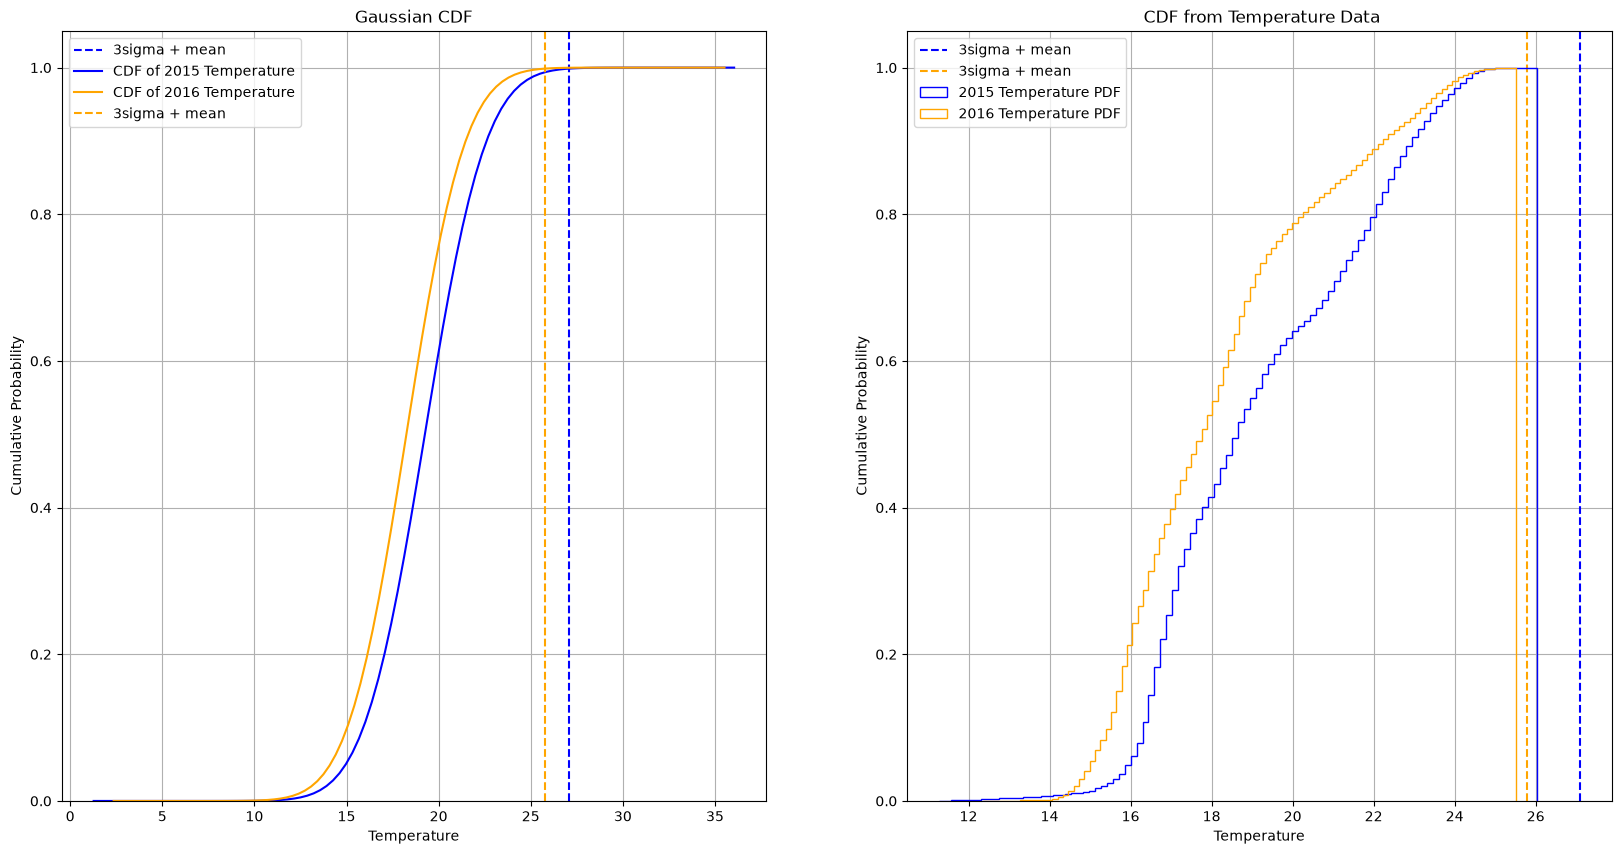

In [18]:
plt.clf()
plt.figure(figsize = (20,10))

plt.subplot(121)
plt.vlines(sigma_times_3_2015_temp,ymin = 0, ymax = 1.2, color = 'blue', linestyle = '--', label = '3sigma + mean')
plt.plot(x15,temperature_cdf_2015, label = 'CDF of 2015 Temperature', color= 'blue')

plt.plot(x16,temperature_cdf_2016,label = 'CDF of 2016 Temperature', color = 'orange')
plt.vlines(sigma_times_3_2016_temp,ymin = 0, ymax = 1.2, color = 'orange',linestyle = '--',label = '3sigma + mean')

plt.legend()
plt.xlabel('Temperature')
plt.ylabel('Cumulative Probability')
plt.title('Gaussian CDF')
plt.ylim(0,1.05)
plt.grid()

plt.subplot(122)
plt.vlines(sigma_times_3_2015_temp,ymin = 0, ymax = 1.2, color = 'blue', linestyle = '--', label = '3sigma + mean')
plt.vlines(sigma_times_3_2016_temp,ymin = 0, ymax = 1.2, color = 'orange',linestyle = '--',label = '3sigma + mean')
plt.hist(data_year_2015.temperature,bins = 100,density='True', cumulative= True, histtype='step', label = '2015 Temperature PDF', color = 'blue')
plt.hist(data_year_2016.temperature,bins = 100,density='True', cumulative= True, histtype='step', label = '2016 Temperature PDF', color = 'orange')
plt.legend()
plt.xlabel('Temperature')
plt.ylabel('Cumulative Probability')
plt.title(' CDF from Temperature Data')
plt.ylim(0,1.05)
plt.grid()

# x = np.linspace(st.norm)
# plt.plot(st.norm.cdf(data_year_2015.temperature))

In [19]:
likelihood_2015 = distribution_2015.cdf(sigma_times_3_2015_temp)
likelihood_2016 = distribution_2015.cdf(sigma_times_3_2016_temp)
print(f'The probability of finding a temperature value three standard deviations out from the mean for 2016 is: { 1- likelihood_2016}')
print(f'The probability of finding a temperature value three standard deviations out from the mean for 2015 is: { 1- likelihood_2015}')

The probability of finding a temperature value three standard deviations out from the mean for 2016 is: 0.0019567497375426735
The probability of finding a temperature value three standard deviations out from the mean for 2015 is: 0.00035610468285618424


The probability of finding a value of temperature that exists three standard deviations greater than the mean is zero in the real data but in the idealized CDf we find that the llikelihood is very small (0.0019 for 2016 and 0.0003 for 2015). 